# Persistent homology and harmonic representatives through the REST API

This notebook shows how to use the REST API in `matilda.api`. It starts a local server, sends it jobs over HTTP and plots what comes back:

1. starting a server
2. persistent homology: barcodes from a point cloud, a distance matrix and an explicit filtration
3. harmonic representatives and harmonic weights
4. errors, limits and job management

It needs matilda with the API dependencies, plus `requests` for the HTTP calls:

    pip install "./matilda-master.zip[api]" requests

In [1]:
import os
import socket
import subprocess
import sys
import tempfile
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import requests
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

import matilda
import matilda.harmonic
import matilda.prototyping

## 1. Starting a server

Usually you start the server from a shell and leave it running:

    python -m matilda.api --port 8000

Here we start it from the notebook, on a free port. Setting `MATILDA_API_MAX_SIMPLICES` lowers the limit on the size of a complex, so that section 4 can show a job going over it. The other limits keep their defaults, which are listed in the README.

In [2]:
with socket.socket() as s:
    s.bind(("127.0.0.1", 0))
    PORT = s.getsockname()[1]
URL = "http://127.0.0.1:{}".format(PORT)

log = open(os.path.join(tempfile.gettempdir(), "matilda-api.log"), "w")
server = subprocess.Popen(
    [sys.executable, "-m", "matilda.api", "--port", str(PORT)],
    env={**os.environ, "MATILDA_API_MAX_SIMPLICES": "100000"},
    stdout=log,
    stderr=subprocess.STDOUT,
)

for _ in range(100):
    try:
        print(requests.get(URL + "/health").json())
        break
    except requests.ConnectionError:
        time.sleep(0.1)
print("interactive documentation at", URL + "/docs")

{'status': 'ok'}
interactive documentation at http://127.0.0.1:43137/docs


## 2. Persistent homology

### A first job, step by step

Every computation is a job. We `POST` the input to `/jobs`; the server checks it, replies `202 Accepted` with the job's id, and computes in the background.

The input here is 60 points near the unit circle, from `matilda.examples`. The server builds their Vietoris-Rips complex up to dimension 2 (`max_dimension`, by default 2) with edges at most `upper_bound` long, and computes its persistent homology over $\mathbb{R}$.

In [3]:
circle = matilda.examples.add_uniform_noise(
    matilda.examples.circle_cloud(res=60), -0.15, 0.15, seed=0
)

response = requests.post(URL + "/jobs", json={"points": circle.tolist(), "upper_bound": 2.0})
print(response.status_code)
job = response.json()
job

202


{'id': '9d4702f0b691496dac62611d27c9bcff',
 'status': 'running',
 'created_at': '2026-10-15T16:25:05.500394+00:00',
 'started_at': '2026-10-15T16:25:05.500667+00:00',
 'finished_at': None,
 'error': None,
 'summary': None}

We poll `GET /jobs/{id}` until the status is `succeeded` (or `failed`). A finished job carries a summary of its input, the size of the complex and the time spent in each step.

In [4]:
while job["status"] in ("queued", "running"):
    time.sleep(0.2)
    job = requests.get(URL + "/jobs/" + job["id"]).json()

print(job["status"])
job["summary"]

succeeded


{'input': {'kind': 'points',
  'n_vertices': 60,
  'dimension': 2,
  'metric': 'euclidean',
  'upper_bound': 2.0,
  'homology_dimension': 1,
  'min_persistence': 0.0,
  'precompute': True},
 'n_simplices': [60, 1546, 23326],
 'n_bars': 62,
 'n_representatives': 2,
 'timings': {'complex': 0.01979050412774086,
  'persistent_homology': 0.33583312993869185,
  'harmonic': 0.003911601845175028}}

`GET /jobs/{id}/barcode` returns every bar. Each bar has an `id`, which is only meaningful within this job, its `dimension`, `birth` and `death` (`None` for an infinite bar), its `persistence`, and the simplices whose addition creates and kills it.

The barcode stops at dimension 1. In a Vietoris-Rips complex cut at dimension 2, every 2-cycle is an infinite bar, so the API leaves the top dimension out.

In [5]:
bars = requests.get(URL + "/jobs/" + job["id"] + "/barcode").json()["bars"]
print(len(bars), "bars")

longest = sorted(bars, key=lambda b: -np.inf if b["death"] is None else -b["persistence"])
for b in longest[:4]:
    print(b)

62 bars
{'id': 0, 'dimension': 0, 'birth': 0.0, 'death': None, 'persistence': None, 'birth_simplex': [0], 'death_simplex': None}
{'id': 295, 'dimension': 1, 'birth': 0.3168571889400482, 'death': 1.5740818977355957, 'persistence': 1.2572247087955475, 'birth_simplex': [22, 23], 'death_simplex': [7, 25, 44]}
{'id': 23, 'dimension': 0, 'birth': 0.0, 'death': 0.29545557498931885, 'persistence': 0.29545557498931885, 'birth_simplex': [23], 'death_simplex': [40, 42]}
{'id': 7, 'dimension': 0, 'birth': 0.0, 'death': 0.27415379881858826, 'persistence': 0.27415379881858826, 'birth_simplex': [7], 'death_simplex': [6, 7]}


The next cell defines plotting helpers. They are not part of the API; they only draw the JSON results.

In [6]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
)
DIMENSION_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # H0, H1, H2
CHAIN_COLOR = "#2a78d6"
WEIGHT_CMAP = matplotlib.colors.LinearSegmentedColormap.from_list(
    "weights", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
    }
)


def dimension_legend(ax, bars, **kwargs):
    dims = sorted({b["dimension"] for b in bars})
    handles = [
        Line2D([], [], color=DIMENSION_COLORS[d], lw=2, marker="o", ms=5, label="H{}".format(d))
        for d in dims
    ]
    ax.legend(handles=handles, **kwargs)


def plot_barcode(bars, ax, max_value):
    # one line per bar, grouped by dimension; infinite bars end in an arrow at max_value
    bars = sorted(bars, key=lambda b: (b["dimension"], b["birth"], b["death"] or np.inf))
    for row, b in enumerate(bars):
        color = DIMENSION_COLORS[b["dimension"]]
        end = max_value if b["death"] is None else b["death"]
        ax.plot([b["birth"], end], [row, row], color=color, lw=2, solid_capstyle="round")
        if b["death"] is None:
            ax.plot(end, row, ">", color=color, ms=6)
    ax.set_xlim(0, max_value * 1.04)
    ax.set_xlabel("filtration value")
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    dimension_legend(ax, bars, loc="lower right")


def plot_diagram(bars, ax, max_value):
    # infinite bars are drawn on a line above max_value
    top = max_value * 1.1
    ax.plot([0, top], [0, top], color=AXIS, lw=1, zorder=1)
    ax.axhline(top, color=AXIS, lw=1, zorder=1)
    for d in sorted({b["dimension"] for b in bars}):
        points = [(b["birth"], top if b["death"] is None else b["death"]) for b in bars if b["dimension"] == d]
        ax.scatter(*zip(*points), s=40, color=DIMENSION_COLORS[d], edgecolors=SURFACE, linewidths=1.5, zorder=3)
    ax.set_xlim(-0.03 * top, top * 1.03)
    ax.set_ylim(-0.03 * top, top * 1.05)
    ticks = [t for t in ax.get_yticks() if 0 <= t <= max_value]
    ax.set_yticks(ticks + [top])
    ax.set_yticklabels(["{:g}".format(t) for t in ticks] + ["∞"])
    ax.set_xlabel("birth")
    ax.set_ylabel("death")
    ax.set_aspect("equal")
    dimension_legend(ax, bars, loc="lower right")


def plot_chain(points, chain, ax, title, all_edges=None, triangles=(), vertices=None):
    # edges of a 1-chain drawn with width proportional to |coefficient|
    for t in triangles:
        ax.fill(*points[list(t)].T, color=CHAIN_COLOR, alpha=0.1, lw=0)
    if all_edges is not None:
        ax.add_collection(LineCollection([points[e] for e in all_edges], colors=AXIS, linewidths=0.8))
    edges = [t for t in chain if len(t["simplex"]) == 2]
    size = np.array([abs(t["coefficient"]) for t in edges])
    ax.add_collection(
        LineCollection(
            [points[t["simplex"]] for t in edges],
            colors=CHAIN_COLOR,
            linewidths=0.5 + 4 * size / size.max(),
            capstyle="round",
            zorder=2,
        )
    )
    shown = points if vertices is None else points[vertices]
    ax.scatter(shown[:, 0], shown[:, 1], s=12, color=MUTED, linewidths=0, zorder=3)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_axis_off()


def plot_weights(points, weights, ax, title):
    # points colored by weight, heaviest drawn on top
    order = np.argsort(weights)
    sc = ax.scatter(
        points[order, 0], points[order, 1], c=np.asarray(weights)[order], cmap=WEIGHT_CMAP,
        vmin=0, s=40, edgecolors=SURFACE, linewidths=1,
    )
    colorbar = ax.figure.colorbar(sc, ax=ax, shrink=0.7, label="harmonic weight")
    colorbar.outline.set_visible(False)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_axis_off()

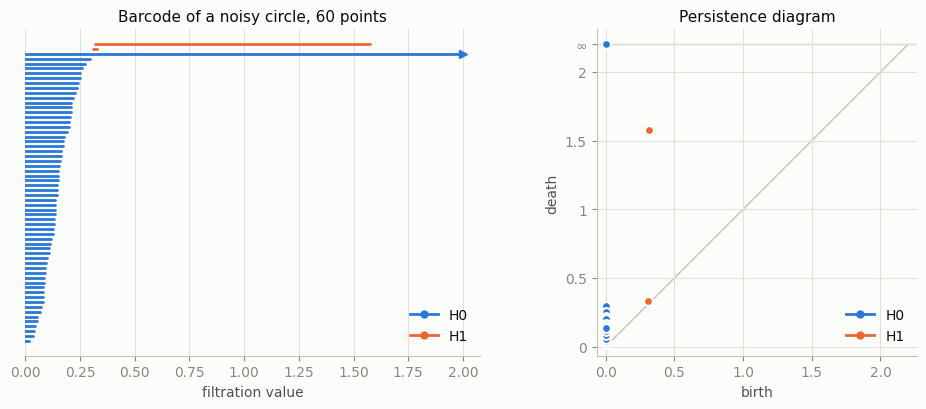

In [7]:
fig, axs = plt.subplots(ncols=2, figsize=(10, 4.2))
plot_barcode(bars, axs[0], max_value=2.0)
axs[0].set_title("Barcode of a noisy circle, 60 points")
plot_diagram(bars, axs[1], max_value=2.0)
axs[1].set_title("Persistence diagram")
fig.tight_layout()
plt.show()

H0 has one infinite bar, because the points end up connected. H1 has one long bar, the circle, which dies at about 1.57 when triangles fill the hole. The short H1 bar is noise.

### Two helpers

From here on, two small functions do the submitting and polling.

In [8]:
def wait(job, poll=0.2):
    # poll a job until it has finished and return its final status
    while job["status"] in ("queued", "running"):
        time.sleep(poll)
        job = requests.get(URL + "/jobs/" + job["id"]).json()
    return job


def run_job(request):
    # submit a job and wait for it; raise if it is rejected or fails
    response = requests.post(URL + "/jobs", json=request)
    if response.status_code != 202:
        raise ValueError(response.json()["detail"])
    job = wait(response.json())
    if job["status"] != "succeeded":
        raise RuntimeError(job["error"])
    return job


def result(job, part):
    # one part of a finished job's result: "barcode", "harmonic" or "weights"
    response = requests.get(URL + "/jobs/" + job["id"] + "/" + part)
    response.raise_for_status()
    return response.json()

### The same complex from a distance matrix, and from matilda directly

A distance matrix gives the same Vietoris-Rips complex, so it gives the same barcode. The API computes it with matilda's own classes, so calling matilda directly also gives the same bars.

In [9]:
dm = matilda.examples.point_cloud_to_metric(circle)
job_dm = run_job({"distance_matrix": dm.tolist(), "upper_bound": 2.0})
bars_dm = result(job_dm, "barcode")["bars"]
print("same barcode from points and from the distance matrix:", bars_dm == bars)

K = matilda.FilteredSimplicialComplex()
K.construct_vietoris_from_metric(dm, 2, 2.0)
homology = matilda.PersistentHomologyComputer()
homology.compute_persistent_homology(K, modulus=0)

direct = sorted((d, birth, death) for d in (0, 1) for birth, death in homology.bars[d].values())
served = sorted((b["dimension"], b["birth"], np.inf if b["death"] is None else b["death"]) for b in bars)
print("same bars as matilda.PersistentHomologyComputer:", np.allclose(direct, served))

same barcode from points and from the distance matrix: True


same bars as matilda.PersistentHomologyComputer: True


### An explicit filtration

Instead of a Vietoris-Rips complex you can give the filtered complex itself: every simplex with the value at which it appears. Every face has to be listed, with a value not larger than its cofaces'. This is the complex of `example_harmonic_persistence.ipynb`. A square 0-1-2-3 has its diagonal 0-2, and its two triangles fill in one after the other.

The birth and death simplices tell you which simplex opens and which one closes each feature.

In [10]:
simplices = [[0], [1], [2], [0, 1], [0, 2], [1, 2], [3], [0, 1, 2], [0, 3], [2, 3], [0, 2, 3]]
values = [0, 1, 2, 3, 3, 3, 4, 5, 6, 6, 7]
filtration = [{"simplex": s, "value": v} for s, v in zip(simplices, values)]

job_square = run_job({"filtration": filtration})
for b in result(job_square, "barcode")["bars"]:
    print(
        "H{}  [{:g}, {})  created by {}, killed by {}".format(
            b["dimension"],
            b["birth"],
            "∞" if b["death"] is None else "{:g}".format(b["death"]),
            b["birth_simplex"],
            b["death_simplex"],
        )
    )

H0  [0, ∞)  created by [0], killed by None
H0  [1, 3)  created by [1], killed by [0, 1]
H0  [2, 3)  created by [2], killed by [0, 2]
H0  [4, 6)  created by [3], killed by [0, 3]
H1  [3, 5)  created by [1, 2], killed by [0, 1, 2]
H1  [6, 7)  created by [2, 3], killed by [0, 2, 3]


Each vertex starts an H0 bar, which ends when an edge joins it to an older component. Vertex 0 is never joined to anything older, so its bar is infinite. Each loop is an H1 bar that ends when a triangle fills it. Bars that are born and die at the same value are not reported. Simplices with equal values are ordered by dimension, then by their position in the list.

Every job also computes harmonic representatives, for the bars of `homology_dimension` (by default 1). If you only need the barcode, raise `min_persistence` so that only a few bars get representatives; section 3 explains it.

## 3. Harmonic representatives

A bar of persistent homology is represented by many cycles. Its **harmonic representative** is the one orthogonal to all boundaries present at the bar's birth (Basu and Cox, *Harmonic persistent homology*). Having no boundary component, it spreads over the simplices around the feature, as the plots below show.

The input is 80 points on a noisy figure eight from `matilda.examples`. The first 40 are on the left loop, the last 40 on the right. `min_persistence=0.3` asks only for the long H1 bars; infinite bars would always be included. `vertex_labels` names the points in the weights output.

In [11]:
eight = matilda.examples.add_uniform_noise(
    matilda.examples.figure_eight_cloud(res=40), -0.15, 0.15, seed=1
)
labels = ["p{}".format(i) for i in range(len(eight))]

job_eight = run_job(
    {
        "points": eight.tolist(),
        "upper_bound": 2.0,
        "homology_dimension": 1,
        "min_persistence": 0.3,
        "vertex_labels": labels,
    }
)
print(job_eight["summary"]["n_bars"], "bars,", job_eight["summary"]["n_representatives"], "harmonic representatives")

harmonic = result(job_eight, "harmonic")
for r in harmonic["representatives"]:
    print("bar {}  [{:.3f}, {:.3f})  {} edges".format(r["bar_id"], r["birth"], r["death"], len(r["chain"])))

89 bars, 2 harmonic representatives
bar 497  [0.426, 1.622)  134 edges
bar 593  [0.468, 1.619)  205 edges


`GET /jobs/{id}/harmonic` returns each representative as a chain: simplices, here edges, with real coefficients. Simplices are named by their vertices. A coefficient's sign is relative to the edge oriented from its smaller to its larger vertex.

In [12]:
harmonic["representatives"][0]["chain"][:5]

[{'simplex': [38, 63], 'coefficient': 0.001245534027101332},
 {'simplex': [49, 50], 'coefficient': 0.2499999999999997},
 {'simplex': [62, 63], 'coefficient': 0.010196015698630982},
 {'simplex': [1, 2], 'coefficient': -0.04853391239821154},
 {'simplex': [40, 41], 'coefficient': 0.5}]

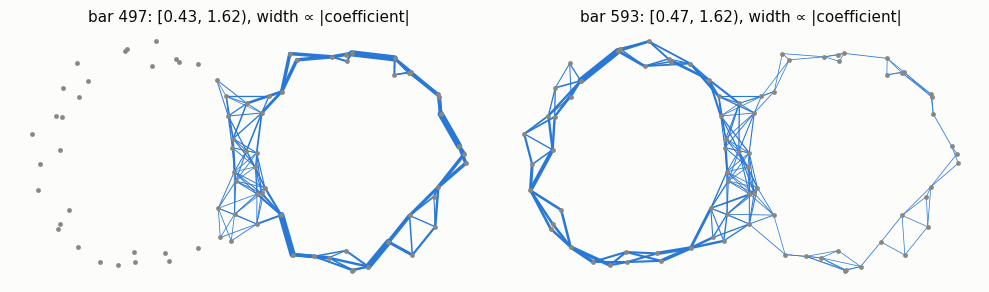

In [13]:
representatives = harmonic["representatives"]
fig, axs = plt.subplots(ncols=len(representatives), figsize=(5 * len(representatives), 3.2))
for ax, r in zip(np.atleast_1d(axs), representatives):
    plot_chain(eight, r["chain"], ax, "bar {}: [{:.2f}, {:.2f}), width ∝ |coefficient|".format(r["bar_id"], r["birth"], r["death"]))
fig.tight_layout()
plt.show()

### Harmonic weights

`GET /jobs/{id}/weights` gives, for each selected bar, the weight of every vertex: the sum of the absolute coefficients of the simplices containing it. This is the per-sample weight used in Gurnari et al., *Probing omics data via harmonic persistent homology*. The weights come as a matrix, one row per bar and one column per vertex, with vertices named by `vertex_labels`.

In [14]:
weights = result(job_eight, "weights")
W = np.array([b["weights"] for b in weights["bars"]])
print(W.shape, "(bars x vertices)")

for b, row in zip(weights["bars"], W):
    heaviest = [weights["vertices"][i] for i in np.argsort(row)[::-1][:5]]
    left = row[:40].sum() / row.sum()
    print(
        "bar {}: {:.0%} of the weight on the left loop, {:.0%} on the right; heaviest vertices {}".format(
            b["bar_id"], left, 1 - left, heaviest
        )
    )

(2, 80) (bars x vertices)
bar 497: 9% of the weight on the left loop, 91% on the right; heaviest vertices ['p78', 'p72', 'p73', 'p66', 'p41']
bar 593: 88% of the weight on the left loop, 12% on the right; heaviest vertices ['p11', 'p13', 'p26', 'p22', 'p33']


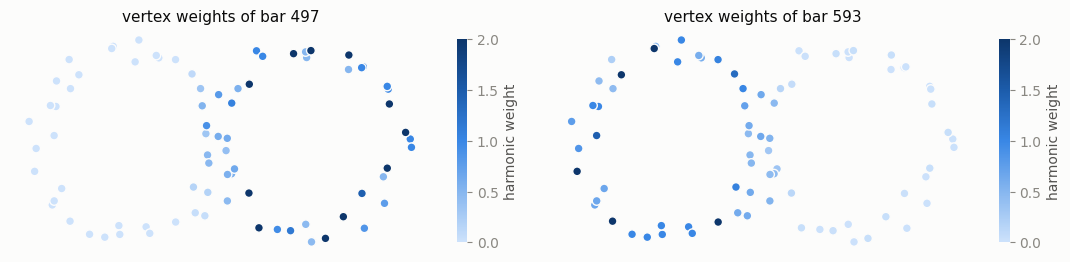

In [15]:
fig, axs = plt.subplots(ncols=len(W), figsize=(5.5 * len(W), 3.2))
for ax, b, row in zip(np.atleast_1d(axs), weights["bars"], W):
    plot_weights(eight, row, ax, "vertex weights of bar {}".format(b["bar_id"]))
fig.tight_layout()
plt.show()

Each long bar puts about 90% of its weight on one loop of the figure eight.

### Harmonic representatives of an explicit filtration

Explicit filtrations work the same way. This is the complex of `examples/harmonic/example_harmonic_1.ipynb`. Edge 1-2 closes the loop 0-1-2 at value 3, and the triangle 0-1-2 fills it at value 5. Vertex 3 appears at value 4. Edges 0-3 and 2-3 join it at value 6, opening the loop 0-2-3, which never closes.

In [16]:
simplices = [[0], [1], [2], [0, 1], [0, 2], [1, 2], [3], [0, 1, 2], [0, 3], [2, 3]]
values = [0, 1, 2, 3, 3, 3, 4, 5, 6, 6]
coords = np.array([[1, 0], [1 / 2, 1], [0, 0], [1 / 2, -1]])

job_kite = run_job({"filtration": [{"simplex": s, "value": v} for s, v in zip(simplices, values)]})
kite = result(job_kite, "harmonic")["representatives"]
for r in kite:
    print("bar {}  [{:g}, {})".format(r["bar_id"], r["birth"], "∞" if r["death"] is None else "{:g}".format(r["death"])))
    for t in r["chain"]:
        print("    {}  {:+.3f}".format(t["simplex"], t["coefficient"]))

bar 5  [3, 5)
    [0, 1]  +1.000
    [0, 2]  -1.000
    [1, 2]  +1.000
bar 9  [6, ∞)
    [0, 1]  +0.333
    [0, 2]  +0.667
    [1, 2]  +0.333
    [0, 3]  -1.000
    [2, 3]  +1.000


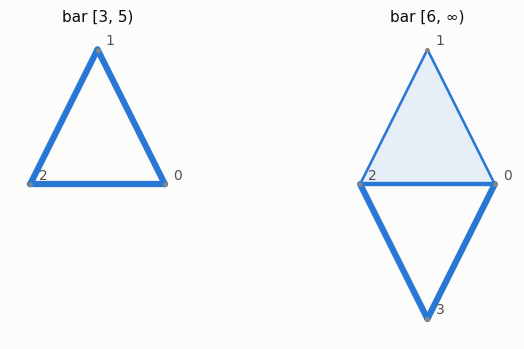

In [17]:
edges = [s for s in simplices if len(s) == 2]
fig, axs = plt.subplots(ncols=len(kite), figsize=(4 * len(kite), 3.6))
for ax, r in zip(axs, kite):
    alive = [s for s, v in zip(simplices, values) if v <= r["birth"]]
    plot_chain(
        coords,
        r["chain"],
        ax,
        "bar [{:g}, {})".format(r["birth"], "∞" if r["death"] is None else "{:g}".format(r["death"])),
        all_edges=[e for e in edges if e in alive],
        triangles=[s for s in alive if len(s) == 3],
        vertices=[s[0] for s in alive if len(s) == 1],
    )
    for [i] in (s for s in alive if len(s) == 1):
        ax.annotate(str(i), coords[i], xytext=(6, 4), textcoords="offset points", color=INK_2)
    ax.set_xlim(coords[:, 0].min() - 0.15, coords[:, 0].max() + 0.15)
    ax.set_ylim(coords[:, 1].min() - 0.15, coords[:, 1].max() + 0.15)
fig.tight_layout()
plt.show()

The infinite bar's harmonic representative is not just the loop 0-2-3. It also has coefficients on edges 0-1 and 1-2, because it must be orthogonal to the boundary of the triangle 0-1-2, which is already filled when the bar is born.

The API returns exactly what matilda's `HarmonicRepresentativesComputer` computes:

In [18]:
K = matilda.prototyping.FilteredSimplicialComplex(
    dimension=2,
    simplices=[np.array(s) for s in simplices],
    simplices_indices=list(range(len(simplices))),
    appears_at=values,
)
homology = matilda.PersistentHomologyComputer()
homology.compute_persistent_homology(K, with_representatives=True, modulus=0)
computer = matilda.harmonic.HarmonicRepresentativesComputer(K, homology)
computer.compute_harmonic_cycles(dim=1, precompute=True)

for r in kite:
    direct = {
        tuple(int(v) for v in K.simplices[i]): c
        for i, c in computer.harmonic_cycles[1][r["bar_id"]].items()
        if c != 0
    }
    served = {tuple(t["simplex"]): t["coefficient"] for t in r["chain"]}
    same = direct.keys() == served.keys() and all(np.isclose(served[s], c) for s, c in direct.items())
    print("bar {}: same as matilda: {}".format(r["bar_id"], same))

bar 5: same as matilda: True
bar 9: same as matilda: True


## 4. Errors, limits and job management

Invalid input is rejected straight away with `422` and a message saying what is wrong.

In [19]:
response = requests.post(URL + "/jobs", json={"points": circle.tolist()})
print(response.status_code, response.json()["detail"])

response = requests.post(URL + "/jobs", json={"filtration": [{"simplex": [0, 1], "value": 0.0}]})
print(response.status_code, response.json()["detail"])

422 'upper_bound' is required for 'points' and 'distance_matrix'
422 face [1] of simplex [0, 1] is missing


The size of a complex is only known once it is built, so that limit is checked inside the job. A job that goes over it fails, and its `error` says why. Asking for its results gives `409 Conflict`. Jobs that crash, run out of memory or exceed the time limit fail the same way, and the server keeps running.

All pairs of 150 random points are closer than `upper_bound`. Their complex has every possible triangle, more than the 100,000 simplices this server allows.

In [20]:
blob = np.random.default_rng(0).uniform(size=(150, 3))
job_big = wait(requests.post(URL + "/jobs", json={"points": blob.tolist(), "upper_bound": 10.0}).json())
print(job_big["status"], "-", job_big["error"])

response = requests.get(URL + "/jobs/" + job_big["id"] + "/barcode")
print(response.status_code, response.json()["detail"])

failed - ValueError: the complex has 562625 simplices, more than the limit of 100000; lower 'upper_bound' or 'max_dimension'
409 job 4ed2dedaa3bb4485b79d65fe234a5ac7 is failed: ValueError: the complex has 562625 simplices, more than the limit of 100000; lower 'upper_bound' or 'max_dimension'


`GET /jobs` lists the jobs the server keeps in memory. `DELETE /jobs/{id}` cancels a job if it is still running and forgets it.

In [21]:
for j in requests.get(URL + "/jobs").json():
    print(j["id"][:8], j["status"], "{} bars".format(j["summary"]["n_bars"]) if j["summary"] else "")

print(requests.delete(URL + "/jobs/" + job_big["id"]).status_code)
print(requests.get(URL + "/jobs/" + job_big["id"]).status_code)

9d4702f0 succeeded 62 bars
47bb0122 succeeded 62 bars
21c03367 succeeded 6 bars
feec038a succeeded 89 bars
cb5872d5 succeeded 6 bars
4ed2deda failed 
204
404


### Without a server

The same computation is a plain function, `matilda.api.compute_harmonic_persistence`. It returns all parts of the result in one dictionary, which is handy in scripts. It does not need the API dependencies.

In [22]:
from matilda.api import compute_harmonic_persistence

local = compute_harmonic_persistence(
    points=eight, upper_bound=2.0, min_persistence=0.3, vertex_labels=labels
)
print(sorted(local))
print("same representatives as the server:", local["harmonic"] == harmonic["representatives"])

['barcode', 'harmonic', 'input', 'n_simplices', 'timings', 'vertex_labels', 'weights']
same representatives as the server: True


Finally, stop the server.

In [23]:
server.terminate()
server.wait()
log.close()